In [2]:
# importing libraries
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
# loading the dataset
df = pd.read_csv(r"G:\datamites\new project\customer-segmentation-retention-analysis\online_retail_II.csv\online_retail_II.csv")

## statistical summary

In [4]:
df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [5]:
df.tail()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
1067366,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France
1067367,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France
1067368,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France
1067369,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680.0,France
1067370,581587,POST,POSTAGE,1,2011-12-09 12:50:00,18.00,12680.0,France


In [6]:
df.shape

(1067371, 8)

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype  
---  ------       --------------    -----  
 0   Invoice      1067371 non-null  str    
 1   StockCode    1067371 non-null  str    
 2   Description  1062989 non-null  str    
 3   Quantity     1067371 non-null  int64  
 4   InvoiceDate  1067371 non-null  str    
 5   Price        1067371 non-null  float64
 6   Customer ID  824364 non-null   float64
 7   Country      1067371 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 65.1 MB


In [8]:
df.describe(include="O")

C:\Users\sahil\AppData\Local\Temp\ipykernel_20624\504318277.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include="O")


,Invoice,StockCode,Description,InvoiceDate,Country
count,1067371,1067371,1062989,1067371,1067371
unique,53628,5305,5698,47635,43
top,537434,85123A,WHITE HANGING HEART T-LIGHT HOLDER,2010-12-06 16:57:00,United Kingdom
freq,1350,5829,5918,1350,981330


In [9]:
df.describe()

,Quantity,Price,Customer ID
count,1.067371e+06,1.067371e+06,824364.000000
mean,9.938898e+00,4.649388e+00,15324.638504
std,1.727058e+02,1.235531e+02,1697.464450
min,-8.099500e+04,-5.359436e+04,12346.000000
25%,1.000000e+00,1.250000e+00,13975.000000
50%,3.000000e+00,2.100000e+00,15255.000000
75%,1.000000e+01,4.150000e+00,16797.000000
max,8.099500e+04,3.897000e+04,18287.000000


In [10]:
df.isnull().sum()

Invoice             0
StockCode           0
Description      4382
Quantity            0
InvoiceDate         0
Price               0
Customer ID    243007
Country             0
dtype: int64

In [11]:
df.duplicated().sum()

np.int64(34335)

In [12]:
df[df.duplicated(keep=False)]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
362,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
363,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
365,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
367,489517,22319,HAIRCLIPS FORTIES FABRIC ASSORTED,12,2009-12-01 11:34:00,0.65,16329.0,United Kingdom
368,489517,22130,PARTY CONE CHRISTMAS DECORATION,6,2009-12-01 11:34:00,0.85,16329.0,United Kingdom
...,...,...,...,...,...,...,...,...
1067136,581538,22068,BLACK PIRATE TREASURE CHEST,1,2011-12-09 11:34:00,0.39,14446.0,United Kingdom
1067150,581538,23318,BOX OF 6 MINI VINTAGE CRACKERS,1,2011-12-09 11:34:00,2.49,14446.0,United Kingdom
1067153,581538,22992,REVOLVER WOODEN RULER,1,2011-12-09 11:34:00,1.95,14446.0,United Kingdom
1067160,581538,22694,WICKER STAR,1,2011-12-09 11:34:00,2.10,14446.0,United Kingdom


In [13]:
for col in df.columns:
    print(f"{col} : {df[col].duplicated().sum()} duplicated values")

Invoice : 1013743 duplicated values
StockCode : 1062066 duplicated values
Description : 1061672 duplicated values
Quantity : 1066314 duplicated values
InvoiceDate : 1019736 duplicated values
Price : 1064564 duplicated values
Customer ID : 1061428 duplicated values
Country : 1067328 duplicated values


## Exploratory Data Analysis

In [14]:
df.Country.nunique()

43

In [15]:
df.Country.unique()

<StringArray>
[      'United Kingdom',               'France',                  'USA',
              'Belgium',            'Australia',                 'EIRE',
              'Germany',             'Portugal',                'Japan',
              'Denmark',              'Nigeria',          'Netherlands',
               'Poland',                'Spain',      'Channel Islands',
                'Italy',               'Cyprus',               'Greece',
               'Norway',              'Austria',               'Sweden',
 'United Arab Emirates',              'Finland',          'Switzerland',
          'Unspecified',                'Malta',              'Bahrain',
                  'RSA',              'Bermuda',            'Hong Kong',
            'Singapore',             'Thailand',               'Israel',
            'Lithuania',          'West Indies',              'Lebanon',
                'Korea',               'Brazil',               'Canada',
              'Iceland',         'Sau

In [16]:
df.Country.value_counts()

Country
United Kingdom          981330
EIRE                     17866
Germany                  17624
France                   14330
Netherlands               5140
Spain                     3811
Switzerland               3189
Belgium                   3123
Portugal                  2620
Australia                 1913
Channel Islands           1664
Italy                     1534
Norway                    1455
Sweden                    1364
Cyprus                    1176
Finland                   1049
Austria                    938
Denmark                    817
Unspecified                756
Greece                     663
Japan                      582
USA                        535
Poland                     535
United Arab Emirates       500
Israel                     371
Hong Kong                  364
Singapore                  346
Malta                      299
Iceland                    253
Canada                     228
Lithuania                  189
RSA                        169


In [17]:
# the percentage of transactions in each country
country_percentage = (
    df['Country']
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
    .reset_index()
)

country_percentage.columns = ['Country', 'Percentage (%)']

country_percentage

,Country,Percentage (%)
0,United Kingdom,91.94
1,EIRE,1.67
2,Germany,1.65
3,France,1.34
4,Netherlands,0.48
5,Spain,0.36
6,Switzerland,0.30
7,Belgium,0.29
8,Portugal,0.25
9,Australia,0.18


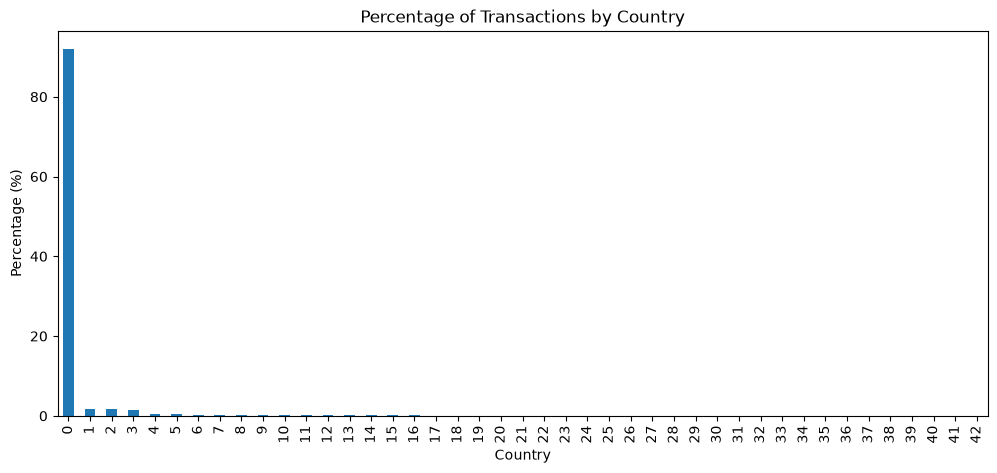

In [18]:
country_percentage['Percentage (%)'].plot(kind='bar', figsize=(12,5))
plt.title('Percentage of Transactions by Country')
plt.xlabel(df['Country'].name)
plt.ylabel('Percentage (%)')
plt.xticks(rotation=90)
plt.show()

### Most of the transaction is from United Kingdom which is around 91 % and other transactions are mostly made by the neighboring countries like Ireland, Germany and France.

In [19]:
#  the transaction period

df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

print(f"Data ranges from {df['InvoiceDate'].min()} to {df['InvoiceDate'].max()}")

Data ranges from 2009-12-01 07:45:00 to 2011-12-09 12:50:00


In [20]:
print(f"Number of transactions regestered : {df['Invoice'].nunique()}")

Number of transactions regestered : 53628


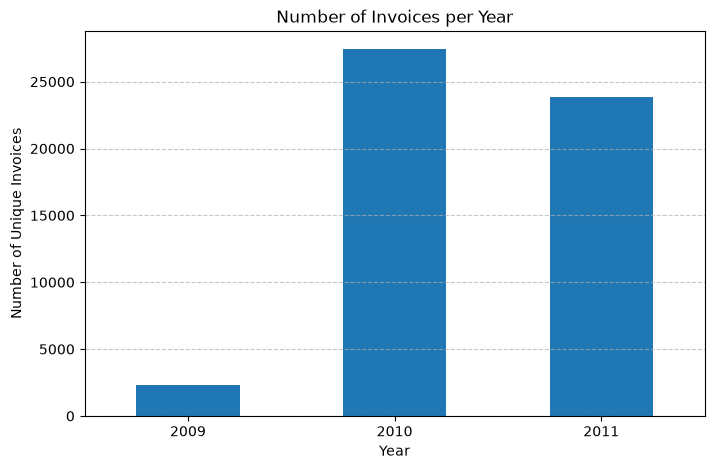

In [21]:
# Convert InvoiceDate to datetime
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

# Extract year
df['Year'] = df['InvoiceDate'].dt.year

# Count unique invoices per year
invoice_per_year = df.groupby('Year')['Invoice'].nunique()

# Plot
plt.figure(figsize=(8,5))
invoice_per_year.plot(kind='bar')

plt.title('Number of Invoices per Year')
plt.xlabel('Year')
plt.ylabel('Number of Unique Invoices')
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.show()

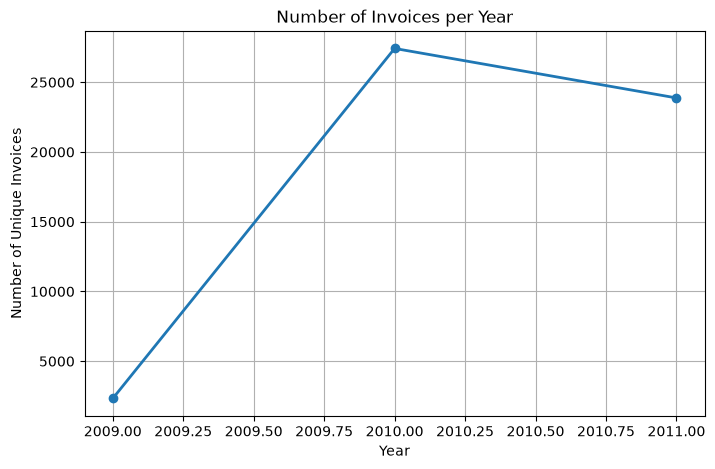

In [22]:
plt.figure(figsize=(8,5))

plt.plot(invoice_per_year.index,
         invoice_per_year.values,
         marker='o',
         linewidth=2)

plt.title('Number of Invoices per Year')
plt.xlabel('Year')
plt.ylabel('Number of Unique Invoices')
plt.grid(True)

plt.show()

In [23]:
print(f"Number of Unique Customers : {df['Customer ID'].nunique()}")

Number of Unique Customers : 5942


In [24]:
df

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Year
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,2009
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,2009
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,2009
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,2009
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,2009
...,...,...,...,...,...,...,...,...,...
1067366,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France,2011
1067367,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France,2011
1067368,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France,2011
1067369,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680.0,France,2011


### Lets see how was the sales in each Month and Monthly Active Customers, then try to answer below questions.

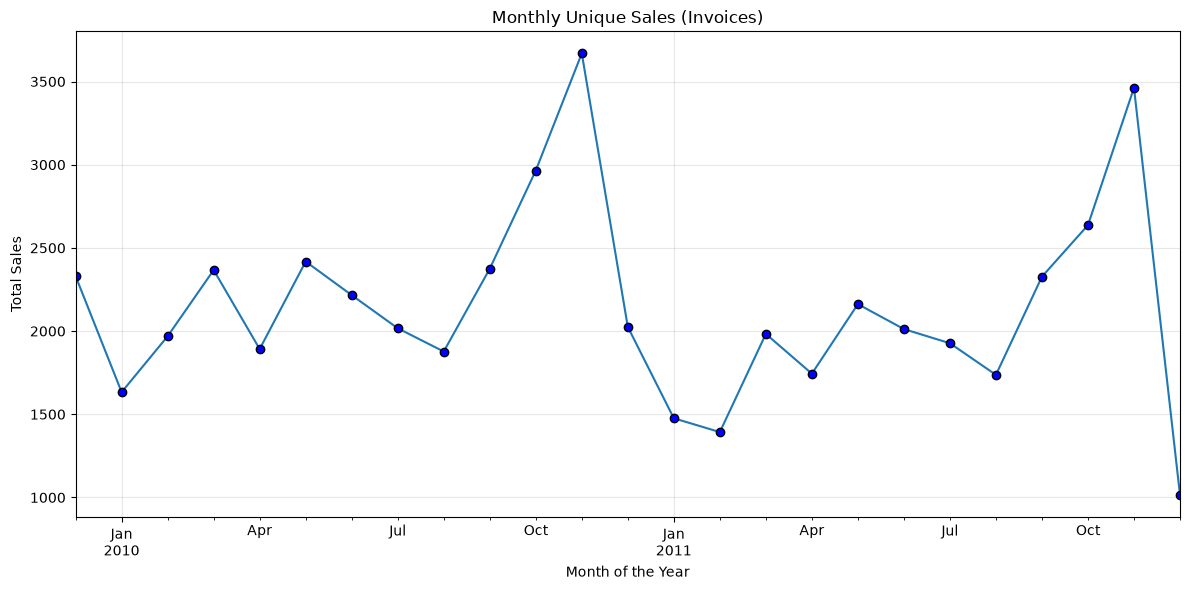

In [25]:
ax = (df.set_index("InvoiceDate").resample("ME")["Invoice"].nunique().plot(figsize=(12, 6),marker="o",linestyle="-",markerfacecolor="blue",markeredgecolor="black"))


ax.set_xlabel("Month of the Year")
ax.set_ylabel("Total Sales")
ax.set_title("Monthly Unique Sales (Invoices)")


ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

#### As expected there is huge increase in transaction during the september to december for both years. Major events like Halloween and Christmas are during that time.

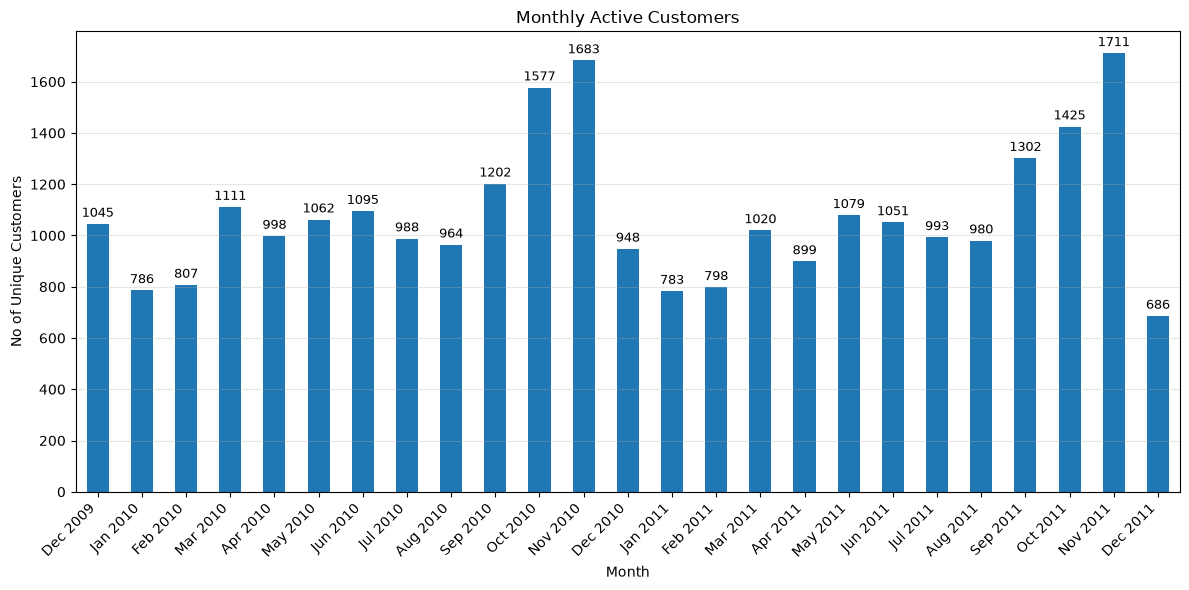

In [26]:
monthly_active = (
    df.set_index("InvoiceDate")
      .resample("ME")["Customer ID"]
      .nunique()
)

ax = monthly_active.plot(kind="bar", figsize=(12, 6))

ax.set_xlabel("Month")
ax.set_ylabel("No of Unique Customers")
ax.set_title("Monthly Active Customers")
ax.grid(axis="y", alpha=0.3)


ax.set_xticklabels(
    monthly_active.index.strftime("%b %Y"),
    rotation=45,
    ha="right"
)


for p in ax.patches:
    ax.annotate(
        int(p.get_height()),
        (p.get_x() + p.get_width() / 2, p.get_height()),
        ha="center",
        va="bottom",
        fontsize=9,
        xytext=(0, 3),
        textcoords="offset points"
    )

plt.tight_layout()
plt.show()

#### We can see the almost similar patterns in both plots. Customer activity and the sales are increasing september to december for both years. Major events like Halloween and Christmas are during that time. We are seeing the spikes due to holidays.

In [27]:
## missing values in the dataset

df.isnull().sum()

Invoice             0
StockCode           0
Description      4382
Quantity            0
InvoiceDate         0
Price               0
Customer ID    243007
Country             0
Year                0
dtype: int64

#### There are 243007 null values as Customer ID and 4382 null values in description. Let first go through the null values in description column.

In [28]:
print(f"Percentage of missing values in Description: {df['Description'].isnull().mean() * 100:.2f}%")

print(f"Percentage of missing values in Customer ID: {df['Customer ID'].isnull().mean() * 100:.2f}%")

Percentage of missing values in Description: 0.41%
Percentage of missing values in Customer ID: 22.77%


#### the percentage of missing value in description is 0.41% and in Customer ID is 22.77%

In [29]:
df[df['Description'].isnull()].sample(10)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Year
38726,492595,21543,NaN,-152,2009-12-17 15:53:00,0.0,NaN,United Kingdom,2009
663368,548175,46115B,NaN,-2,2011-03-29 14:19:00,0.0,NaN,United Kingdom,2011
672063,549003,21279,NaN,14,2011-04-05 14:36:00,0.0,NaN,United Kingdom,2011
79742,496638,51012C,NaN,12,2010-02-03 11:08:00,0.0,NaN,United Kingdom,2010
793931,560423,16169K,NaN,-25,2011-07-18 15:15:00,0.0,NaN,United Kingdom,2011
267587,515297,22656,NaN,-1,2010-07-09 15:23:00,0.0,NaN,United Kingdom,2010
200928,508682,84656,NaN,-1,2010-05-17 16:43:00,0.0,NaN,United Kingdom,2010
608289,543266,82095,NaN,-5,2011-02-04 17:24:00,0.0,NaN,United Kingdom,2011
3114,489655,20683,NaN,-44,2009-12-01 17:26:00,0.0,NaN,United Kingdom,2009
192249,507645,84858A,NaN,-6,2010-05-10 15:28:00,0.0,NaN,United Kingdom,2010


In [30]:
all(df[df["Description"].isnull()]["Customer ID"].isnull())

True

#### all rows that have a missing Description also missing a Customer ID

In [31]:
(df[df["Description"].isnull()]["Quantity"] <= 0).mean() * 100

np.float64(61.364673664993155)

In [32]:
df[(df["Description"].isnull()) & (df["Country"] == "United Kingdom")].shape[0]

4382

In [33]:
all(df[df["Description"].isnull()]["Country"] == "United Kingdom")

True

In [34]:
df[(df["Description"].isnull()) & (df["Price"] == 0.0)].shape[0]

4382

In [35]:
all(df[df["Description"].isnull()]["Price"] == 0.0)

True

#### All records where the description is null in the same record price is 0.0 , quantity is negative and country of transaction is United Kingdom. This might be due returns, cancellation or refunds. 

In [36]:
df[df['Customer ID'].isnull()].sample(10)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Year
163218,504916,22219,LOVEBIRD HANGING DECORATION WHITE,2,2010-04-19 10:28:00,1.66,NaN,United Kingdom,2010
142097,502872,84452,METAL RABBIT LADDER EASTER,1,2010-03-29 09:59:00,1.66,NaN,United Kingdom,2010
600472,542541,84992,72 SWEETHEART FAIRY CAKE CASES,1,2011-01-28 14:25:00,1.25,NaN,United Kingdom,2011
682901,550205,20963,APPLE BATH SPONGE,1,2011-04-15 10:37:00,2.46,NaN,United Kingdom,2011
828987,563549,21172,PARTY METAL SIGN,3,2011-08-17 12:34:00,4.13,NaN,United Kingdom,2011
648941,546896,22200,FRYING PAN PINK POLKADOT,1,2011-03-17 18:24:00,8.29,NaN,United Kingdom,2011
683306,550213,22720,SET OF 3 CAKE TINS PANTRY DESIGN,1,2011-04-15 10:42:00,10.79,NaN,United Kingdom,2011
1003376,577078,23000,TRAVEL CARD WALLET TRANSPORT,1,2011-11-17 15:17:00,0.83,NaN,United Kingdom,2011
855745,565917,22963,JAM JAR WITH GREEN LID,1,2011-09-07 16:15:00,1.63,NaN,United Kingdom,2011
191070,507448,84529C,YELLOW KNITTED KIDS RUCKSACK,1,2010-05-10 09:55:00,4.21,NaN,United Kingdom,2010


In [37]:
all(df[df["Customer ID"].isnull()]["Description"].isnull())

False

In [38]:
df[df["Customer ID"].isnull()]["Description"].nunique()

4872

In [39]:
(df[df["Customer ID"].isnull()]["Quantity"] <= 0).mean() * 100

np.float64(1.7308143386816017)

In [40]:
df[(df["Customer ID"].isnull()) & (df["Price"] == 0.0)].shape[0]

6131

In [41]:
(df[df["Customer ID"].isnull()]["Price"] == 0.0).mean() *100

np.float64(2.522972589266976)

In [42]:
df[(df["Customer ID"].isnull()) & (df["Country"] == "United Kingdom")].shape[0]

240029

In [43]:
print (f"Percentage of missing Customer IDs in United Kingdom: {df[(df['Customer ID'].isnull()) & (df['Country'] == 'United Kingdom')].shape[0] / (df['Customer ID'].isnull().sum())*100:.2f}%")

Percentage of missing Customer IDs in United Kingdom: 98.77%


#### We didn't identify any clear pattens with the null values in Customer ID. As it is scattered and some are having price is 0.0 and quantity is negative. Since the majority of transaction is from United Kingdom. United Kingdom has contributed 98.77 % of null value.

#### while exploring the other things i noticed that there were prices with 0.0 and quantity with negative values.

In [44]:
(df["Price"] <= 0).mean() * 100

np.float64(0.5815222635803297)

In [45]:
(df["Price"] <= 0).sum()

np.int64(6207)

In [46]:
(df["Quantity"] <= 0).mean() * 100

np.float64(2.1501427338760375)

In [47]:
(df["Quantity"] <= 0).sum()

np.int64(22950)

#### There are 6207 records where price is less than 0 and 22950 records where quantity is less than 0 or 0. Let's see the sample data where quantity is less than 0 or 0.

In [48]:
df[df["Quantity"] <= 0].sample(10)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Year
1057266,C580968,23523,WALL ART TREASURE AHOY,-6,2011-12-06 14:57:00,3.75,15622.0,United Kingdom,2011
448885,C532086,35004B,SET OF 3 BLACK FLYING DUCKS,-3,2010-11-10 15:26:00,1.95,14031.0,United Kingdom,2010
131274,C501861,20784,RED RETRO BAR STOOL,-1,2010-03-21 11:36:00,39.95,14080.0,United Kingdom,2010
343807,C522951,21659,GLASS CAKE STAND,-1,2010-09-19 11:21:00,14.95,13617.0,United Kingdom,2010
532672,537019,37474,NaN,-15,2010-12-03 15:43:00,0.00,NaN,United Kingdom,2010
414639,C528984,71477,COLOUR GLASS. STAR T-LIGHT HOLDER,-1,2010-10-26 11:04:00,3.25,18247.0,United Kingdom,2010
590067,C541656,21528,DAIRY MAID TRADITIONAL TEAPOT,-1,2011-01-20 12:07:00,6.95,17315.0,United Kingdom,2011
545962,C538059,48187,DOORMAT NEW ENGLAND,-2,2010-12-09 13:38:00,7.95,14205.0,United Kingdom,2010
379571,C525954,22244,3 HOOK HANGER MAGIC GARDEN,-1,2010-10-07 19:27:00,1.95,12472.0,Germany,2010
596978,C542138,20866,BLUE ROSE FABRIC MIRROR,-120,2011-01-25 17:21:00,1.06,17368.0,United Kingdom,2011


#### While the sample we shall notice that some of the invoices are starting with "C". That indicates some cancellation has happened or invoice has been cancelled. Lets check what percentage of invoice starts with C against the total number of records where the quantity is less than 0 or 0.

In [49]:
print(f"Percentage of negative quantity values that start with 'C': {df[df['Quantity'] <= 0]['Invoice'].astype('str').str.startswith('C').mean() * 100:.2f}%")

Percentage of negative quantity values that start with 'C': 84.94%


In [50]:
(df[df["Invoice"].astype("str").str.startswith("C")]["Quantity"] <= 0.).mean() * 100

np.float64(99.99487021647685)

#### So here we can see 99% of invoice starting with C is having quantity 0 or negative.

# Data Cleaning & Transformation

In [51]:
df.isnull().sum()

Invoice             0
StockCode           0
Description      4382
Quantity            0
InvoiceDate         0
Price               0
Customer ID    243007
Country             0
Year                0
dtype: int64

In [52]:
missing_data = df.isnull().sum()
missing_data_percent = missing_data[missing_data>0] / df.shape[0] *100
missing_data_percent

Description     0.410541
Customer ID    22.766873
dtype: float64

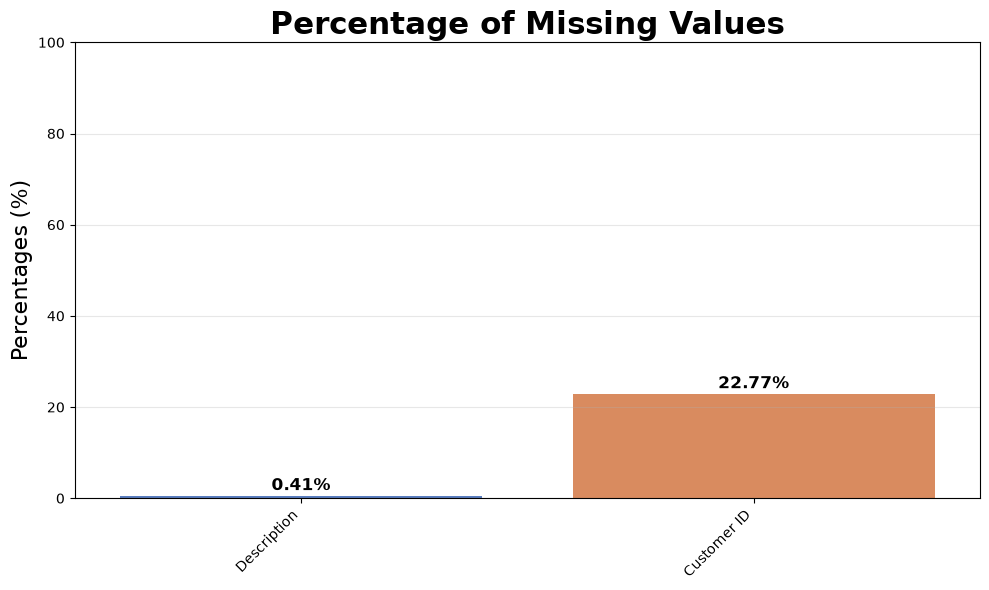

In [53]:
missing_data_percent = missing_data_percent.sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(10, 6))

sns.barplot(x=missing_data_percent.index, y=missing_data_percent.values, hue=missing_data_percent.index,palette="muted",legend=False,ax=ax)



for i, value in enumerate(missing_data_percent.values):
    ax.text(i,value + 0.5,f"{value:.2f}%",ha="center",va="bottom",fontsize=12,fontweight="bold",color="black")

ax.set_ylim(0, 100)
ax.set_title("Percentage of Missing Values", fontsize=22, fontweight="bold")
ax.set_ylabel("Percentages (%)", fontsize=16)
ax.set_xlabel("")


plt.setp(ax.get_xticklabels(), rotation=45, ha="right")

ax.grid(axis="y", alpha=0.3)

plt.tight_layout() 
plt.show()

#### As we can observe from the above graph Customer ID is having almost 25% of missing values. Its not recommended to impute such a large percentage of missing values this might cause bias or noise to the analysis.
#### Description is having very negligible amount of missing values. Since it is a low impact categorical features, we have two options: Can drop this as the impact is less or can impute as "Unknown" and can be used as categorical feature. In this case i am imputing as "Unknown" for description and drop the Customer ID.

In [54]:
df["Description"] = df["Description"].fillna("Unknown")
df = df.dropna(subset=['Customer ID'])

In [55]:
df.isnull().sum().sum()

np.int64(0)

In [56]:
df.shape

(824364, 9)

### Handling Duplicates

In [57]:
df.duplicated().sum()

np.int64(26479)

#### There are 26479 duplicate rows in the dataset.As we know the accuracy of the Data is important for the prediction. It is important to remove these duplicates other it will result unwanted noise in the dataset.
#### Removing these rows will help in achieving a cleaner dataset.

In [58]:
df.drop_duplicates(inplace=True)

In [59]:
df.shape

(797885, 9)

### Treating Cancelled Transactions

In [60]:
df

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Year
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,2009
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,2009
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,2009
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,2009
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,2009
...,...,...,...,...,...,...,...,...,...
1067366,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France,2011
1067367,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France,2011
1067368,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France,2011
1067369,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680.0,France,2011


In [61]:
df['Transaction_Status'] = np.where(df['Invoice'].astype(str).str.startswith('C'), 'Cancelled', 'Completed')
cancelled_transactions = df[df['Transaction_Status'] == 'Cancelled']
cancelled_transactions.describe().drop(['Customer ID','InvoiceDate','Year'], axis=1)

,Quantity,Price
count,18390.000000,18390.000000
mean,-25.719195,24.240567
min,-80995.000000,0.010000
25%,-6.000000,1.450000
50%,-2.000000,2.950000
75%,-1.000000,5.950000
max,-1.000000,38970.000000
std,825.979381,428.241509


In [62]:
cancelled_percentage = (cancelled_transactions.shape[0] / df.shape[0]) * 100
print(f"The percentage of cancelled transactions in the dataset is: {cancelled_percentage:.2f}%")

The percentage of cancelled transactions in the dataset is: 2.30%


#### All the quantity values that are negative correspond to cancelled transactions. The item value range from 0.01 to 38970 which indicate that the all items from low to high were cancelled. So it is recommended to retain this data as there will be some patterns and trends in cancellation that will be helpful in identifying the customer behavior.

### StockCode Anomalies correction

In [63]:
unique_stock_codes = df['StockCode'].nunique()
print(f"The number of unique stock codes in the dataset is: {unique_stock_codes}")

The number of unique stock codes in the dataset is: 4646


In [64]:
top_10_stock_codes = df["StockCode"].value_counts(normalize=True).head(10)
print(f"The top 10 most frequent stock codes are: {top_10_stock_codes}")

The top 10 most frequent stock codes are: StockCode
85123A    0.006462
22423     0.004610
85099B    0.004236
84879     0.003395
20725     0.003366
21212     0.003236
21232     0.002660
47566     0.002658
20727     0.002618
22383     0.002594
Name: proportion, dtype: float64


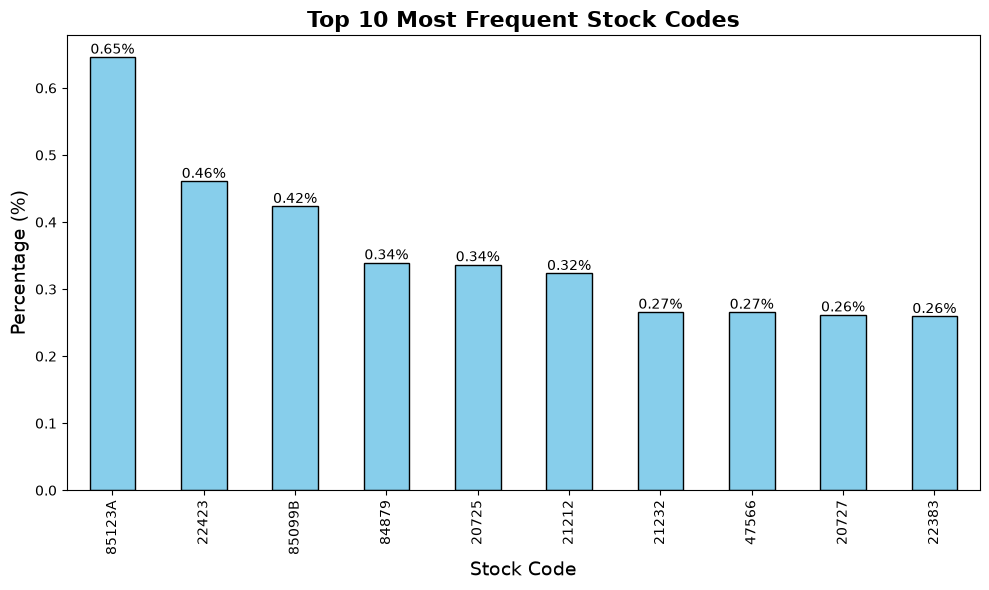

In [65]:
plt.figure(figsize=(10, 6))
ax = (top_10_stock_codes * 100).plot(kind='bar',color='skyblue',edgecolor='black')
ax.set_title('Top 10 Most Frequent Stock Codes', fontsize=16, fontweight='bold')
ax.set_xlabel('Stock Code', fontsize=14)        
ax.set_ylabel('Percentage (%)', fontsize=14)


for i, val in enumerate(top_10_stock_codes * 100):
    ax.text(i, val, f"{val:.2f}%", ha='center', va='bottom')

plt.tight_layout()
plt.show()

#### The dataset is having 4646 unique stock code that is showing that the there is different range of products in the dataset. This will be used to understand the behavior of the customer. Exploring the top 10 frequent stock code will help to customer purchase frequency. Let's check if there is any anomaly in stock code.

In [66]:
unique_stock_codes = df['StockCode'].unique()
numeric_char_counts_in_unique_codes = pd.Series(unique_stock_codes).apply(lambda x: sum(c.isdigit() for c in str(x))).value_counts()


print("Value counts of numeric character frequencies in unique stock codes:")
print("-"*70)
print(numeric_char_counts_in_unique_codes)

Value counts of numeric character frequencies in unique stock codes:
----------------------------------------------------------------------
5    4633
0       8
1       2
3       2
4       1
Name: count, dtype: int64


#### There are 4633 codes is having 5 numeric values and others are not in that pattern. Need to check which are those to confirm whether it is an anomaly or not.

In [67]:
anomalous_stock_codes  = [ code for code in unique_stock_codes if sum(c.isdigit() for c in str(code))<=4]

print("Anomalous stock codes:")
print("-"*22)

for code in anomalous_stock_codes:
    print(code)

Anomalous stock codes:
----------------------
POST
D
M
C2
BANK CHARGES
TEST001
TEST002
PADS
ADJUST
ADJUST2
SP1002
DOT
CRUK


In [68]:
percentage_anomalous = (df['StockCode'].isin(anomalous_stock_codes).sum() / len(df) * 100)
print(f"Percentage of anomalous stock codes: {percentage_anomalous:.2f}%")

Percentage of anomalous stock codes: 0.46%


#### Total percentage of stock codes which are anomalous are 0.46 % which is very less compared to dataset. These are some Bank Charges, Post, Test etc which does not represent the actual data and this does not seem to be related to product purchase and need to be removed.

In [69]:
df = df[~df['StockCode'].isin(anomalous_stock_codes)]

In [70]:
df.shape[0]

794223

### Cleaning Description Column

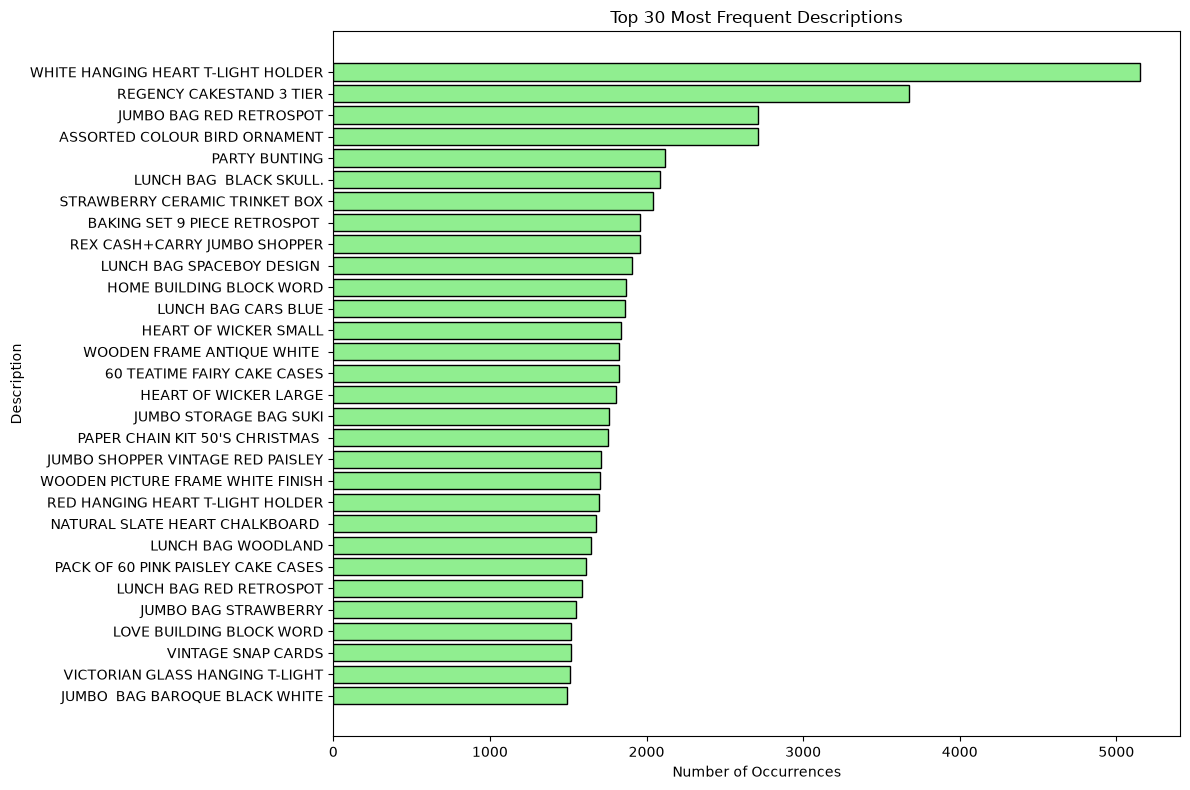

In [71]:
description_counts = df['Description'].value_counts()

top_30_descriptions = description_counts[:30]

plt.figure(figsize=(12,8))
plt.barh(top_30_descriptions.index[::-1], top_30_descriptions.values[::-1], color='lightgreen', edgecolor='black')


plt.xlabel('Number of Occurrences')
plt.ylabel('Description')
plt.title('Top 30 Most Frequent Descriptions')

plt.tight_layout()
plt.show()

#### The top 30 most frequent descriptions are household items, kitchenware, lunch bags, and decorative items. We can see these descriptions are in upper case. So it should be standard to mention in upper case. Let's check whether any description is in lower case.

In [72]:
lowercase_descriptions = [desc for desc in df['Description'].unique() if any (char.islower() for char in str(desc))]

print("The unique descriptions containing lowercase characters are:")
print("-"*60)

for desc in lowercase_descriptions:
    print(desc)

The unique descriptions containing lowercase characters are:
------------------------------------------------------------
BAG 500g SWIRLY MARBLES
POLYESTER FILLER PAD 40x40cm
POLYESTER FILLER PAD 60x40cm
POLYESTER FILLER PAD 65CMx65CM
POLYESTER FILLER PAD 45x45cm
BAG 125g SWIRLY MARBLES
ESSENTIAL BALM 3.5g TIN IN ENVELOPE
FOLK ART GREETING CARD,pack/12
BAG 250g SWIRLY MARBLES
POLYESTER FILLER PAD 30CMx30CM
POLYESTER FILLER PAD 45x30cm
 SET Of 6 SOLDIER SKITTLES
THE KING GIFT BAG 25x24x12cm
FRENCH BLUE METAL DOOR SIGN, No
NUMBER TILE COTTAGE GARDEN, No
NUMBER TILE VINTAGE FONT, No 
NUMBER TILE VINTAGE FONT No 
FRENCH BLUE METAL DOOR SIGN No
NUMBER TILE COTTAGE GARDEN No
3 TRADITIONAl BISCUIT CUTTERS  SET
FLOWERS HANDBAG blue and orange
Next Day Carriage
High Resolution Image


#### While looking at the lowercase character description, its clear that there are 2 service related description "Next Day Carriage" and "High Resolution Image". This need to be removed as this will only create noise in the model. Remaining description need to standardized to upper case in order to make sure the description follow a standard format. 

In [73]:
service_related_descriptions = ['Next Day Carriage', 'High Resolution Image']

service_related_description_percentage = (df['Description'].isin(service_related_descriptions).sum() / len(df)) * 100
print(f"Percentage of service-related descriptions: {service_related_description_percentage:.2f}%")

Percentage of service-related descriptions: 0.01%


In [74]:
df = df[~df['Description'].isin(service_related_descriptions)]

df['Description'] = df['Description'].str.upper()

df.shape[0]

794140

### Treating Zero Unit Prices

In [75]:
df[df['Price']==0].value_counts().sum()

np.int64(60)

In [76]:
df['Price'].describe()

count    794140.000000
mean          2.969938
std           4.473401
min           0.000000
25%           1.250000
50%           1.950000
75%           3.750000
max         649.500000
Name: Price, dtype: float64

In [77]:
df[df['Price']==0].describe()[['Quantity']]

,Quantity
count,60.000000
mean,245.583333
min,1.000000
25%,2.000000
50%,7.000000
75%,21.000000
max,12540.000000
std,1616.970743


#### In these transactions the quantity ranges from 1 to 12540. Including these 60 records will create more noise and will be effecting our model. So we need to remove this to make the dataset more cleaner.

In [78]:
df = df[df['Price']>0]

In [79]:
df.reset_index(drop=True, inplace=True)

In [80]:
df.shape[0]

794080